# How omitted confounding distorts performance

Suppose an exposure and outcome are generated by a common cause according to:

$$
X=\delta Z+V,
\qquad
Y=\beta X+\gamma Z+U,
\qquad
\widetilde\beta
=\beta+\frac{\gamma\delta}{1+\delta^2}.
$$

Here, $Z$ is the omitted common cause, $X$ is the exposure, $Y$ is the outcome, $V$ and $U$ are independent centered disturbances with unit variance, $\delta$ links $Z$ to $X$, $\beta$ is the direct effect of $X$ on $Y$, $\gamma$ links $Z$ to $Y$, and $\widetilde\beta$ is the population coefficient from regressing $Y$ on $X$ while omitting $Z$.

,Direct effect,Common-cause outcome link,Common-cause exposure link,Omitted coefficient,Omission bias,Formula difference
0,1,3,1,2.5,1.5,0
1,-0.7,1.2,-0.4,-1.113793,-0.413793,0
2,0,-2,3,-0.6,-0.6,0
3,2.5,0,-8,2.5,0,0


,Specification,Exposure coefficient,Population target,Explained variance,Observations,Seed
0,Common cause omitted,2.491882,2.5,0.693785,5000,0
1,Common cause included,1.00072,1,0.943705,5000,0


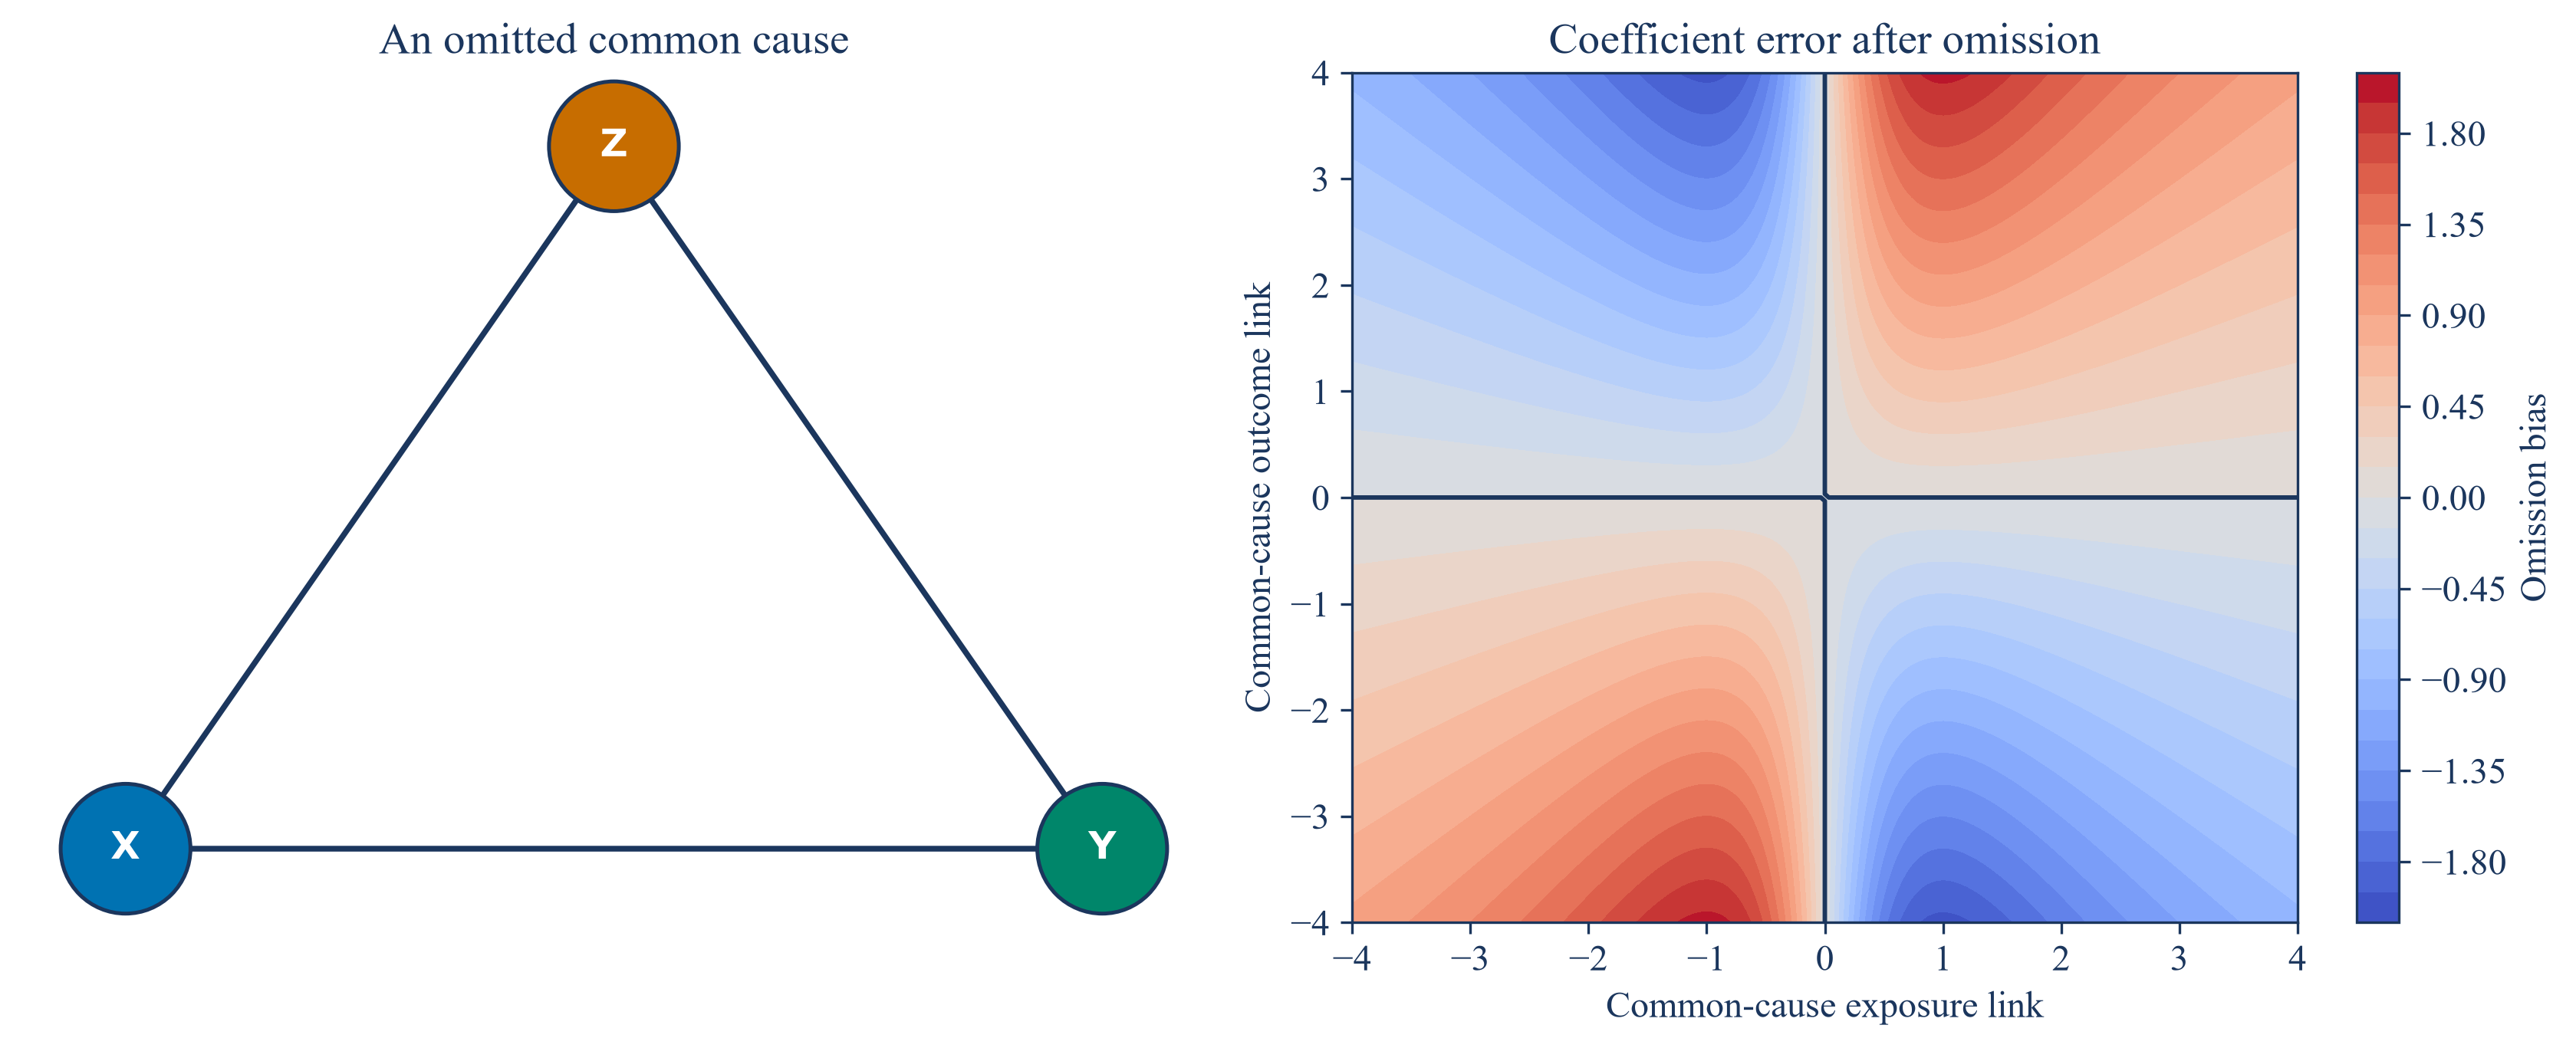

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
from dataclasses import FrozenInstanceError
import inspect
import math
import re
import sys
import warnings
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import Image

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parents[1]

from RiskLabAI.causal_factor_analysis import ColliderCoefficients, ColliderDiagnostics, PopulationRegressionDiagnostics, RegressionDiagnostics, SpecificationExperimentResult, SpecificationPopulationResult, StrategyPerformance, collider_factor_return, collider_forecast_return, collider_model_diagnostics, collider_overcontrolled_coefficients, collider_population_diagnostics, collider_specification_experiment, confounded_mediator_population_diagnostics, confounded_mediator_specification_experiment, confounder_factor_return, confounder_forecast_return, confounder_undercontrolled_coefficient, fork_population_diagnostics, fork_specification_experiment, generalized_collider_overcontrolled_coefficients, generalized_confounder_undercontrolled_coefficient

FIGURES = ROOT / "outputs" / "figures" / "04_factor_mirage"
TABLES = ROOT / "outputs" / "tables" / "04_factor_mirage"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

palette = {"background": "#FFFFFF", "axes": "#FFFFFF", "text": "#1B365D", "cyan": "#0072B2", "amber": "#C76D00", "green": "#00866A", "rose": "#B83B3B", "violet": "#A03A78", "grid": "#D9DEE5", "muted": "#5C6670"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def display_float(value):
    if not np.isfinite(value):
        return str(value)
    nearest_integer = round(float(value))
    if np.isclose(value, nearest_integer, atol=1e-12):
        return str(int(nearest_integer))
    if abs(value) < 5e-13:
        return "0"
    return f"{value:.6f}".rstrip("0").rstrip(".")

pd.set_option("display.float_format", display_float)

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True, position="tbp"):
    table_frame = frame.copy()
    for column in table_frame.columns:
        if pd.api.types.is_bool_dtype(table_frame[column]):
            table_frame[column] = table_frame[column].map({True: "Yes", False: "No"})
    table_frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(table_frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position=position))
    if fit:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{adjustbox}{max width=\textwidth}" + "\n" + r"\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}" + "\n" + r"\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    latex = re.sub(r"(?<![A-Za-z])(?:nan|NaN)(?![A-Za-z])", "Not available", latex)
    latex = re.sub(r"(?<![A-Za-z])inf(?![A-Za-z])", "No finite value", latex)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

def save_figure(figure, stem):
    figure.savefig(FIGURES / f"{stem}.png", bbox_inches="tight", dpi=300)
    figure.savefig(FIGURES / f"{stem}.pdf", bbox_inches="tight")
    display(Image(filename=str(FIGURES / f"{stem}.png")))
    plt.close(figure)

def contract_result(name, action, expected):
    try:
        action()
        return {"Check": name, "Expected result": expected, "Observed result": "Accepted", "Passed": False}
    except Exception as error:
        return {"Check": name, "Expected result": expected, "Observed result": type(error).__name__, "Passed": type(error).__name__ == expected}

def draw_graph(axis, nodes, edges, positions, title, colors=None):
    graph = nx.DiGraph()
    graph.add_nodes_from(nodes)
    graph.add_edges_from(edges)
    node_colors = colors if colors is not None else [palette["cyan"]] * len(nodes)
    nx.draw_networkx_nodes(graph, positions, ax=axis, node_color=node_colors, node_size=1650, edgecolors=palette["text"], linewidths=1.2)
    nx.draw_networkx_labels(graph, positions, ax=axis, font_color=palette["background"], font_weight="bold")
    nx.draw_networkx_edges(graph, positions, ax=axis, edge_color=palette["text"], width=1.8, arrows=True, arrowsize=20)
    axis.set_title(title)
    axis.set_axis_off()

def ols_diagnostics(outcome, predictors):
    design = np.column_stack([np.ones(len(outcome))] + [np.asarray(values, dtype=float) for values in predictors.values()])
    coefficients = np.linalg.lstsq(design, np.asarray(outcome, dtype=float), rcond=None)[0]
    residuals = np.asarray(outcome, dtype=float) - design @ coefficients
    residual_degrees = len(outcome) - design.shape[1]
    residual_variance = float(residuals @ residuals / residual_degrees)
    covariance = np.linalg.inv(design.T @ design) * residual_variance
    standard_errors = np.sqrt(np.diag(covariance))
    centered = np.asarray(outcome, dtype=float) - np.mean(outcome)
    r_squared = 1.0 - float(residuals @ residuals) / float(centered @ centered)
    adjusted = 1.0 - (1.0 - r_squared) * (len(outcome) - 1) / residual_degrees
    names = ["Intercept"] + list(predictors)
    return pd.DataFrame({"Coefficient": names, "Estimate": coefficients, "Standard error": standard_errors, "Test signal": coefficients / standard_errors}), r_squared, adjusted, residual_variance

def coefficient_value(diagnostics, name):
    return diagnostics.coefficients[diagnostics.coefficient_names.index(name)]

standardized_cases = [(1.0, 3.0, 1.0), (-0.7, 1.2, -0.4), (0.0, -2.0, 3.0), (2.5, 0.0, -8.0)]
standardized_rows = []
for beta, gamma, delta in standardized_cases:
    library_value = confounder_undercontrolled_coefficient(beta, gamma, delta)
    direct_value = beta + gamma * delta / (1.0 + delta ** 2)
    standardized_rows.append({"Direct effect": beta, "Common-cause outcome link": gamma, "Common-cause exposure link": delta, "Omitted coefficient": library_value, "Omission bias": library_value - beta, "Formula difference": library_value - direct_value})
standardized_table = pd.DataFrame(standardized_rows)
save_table(standardized_table, "confounder_standardized_coefficients", "Standardized omitted-confounder coefficients.", "tab:chapter26-confounder-standardized")
display(standardized_table)

beta = 1.0
gamma = 3.0
delta = 1.0
sample_size = 5000
random_state = np.random.RandomState(0)
common_cause = random_state.standard_normal(sample_size)
exposure_noise = random_state.standard_normal(sample_size)
outcome_noise = random_state.standard_normal(sample_size)
exposure = delta * common_cause + exposure_noise
outcome = beta * exposure + gamma * common_cause + outcome_noise
unconditioned_diagnostics, unconditioned_r2, _, _ = ols_diagnostics(outcome, {"Exposure": exposure})
conditioned_diagnostics, conditioned_r2, _, _ = ols_diagnostics(outcome, {"Exposure": exposure, "Common cause": common_cause})
generated_table = pd.DataFrame([
    {"Specification": "Common cause omitted", "Exposure coefficient": unconditioned_diagnostics.loc[1, "Estimate"], "Population target": confounder_undercontrolled_coefficient(beta, gamma, delta), "Explained variance": unconditioned_r2, "Observations": sample_size, "Seed": 0},
    {"Specification": "Common cause included", "Exposure coefficient": conditioned_diagnostics.loc[1, "Estimate"], "Population target": beta, "Explained variance": conditioned_r2, "Observations": sample_size, "Seed": 0},
])
save_table(generated_table, "confounder_generated_check", "A visible fixed-seed confounder experiment.", "tab:chapter26-confounder-generated")
display(generated_table)

gamma_grid = np.linspace(-4.0, 4.0, 241)
delta_grid = np.linspace(-4.0, 4.0, 241)
gamma_mesh, delta_mesh = np.meshgrid(gamma_grid, delta_grid)
bias_mesh = gamma_mesh * delta_mesh / (1.0 + delta_mesh ** 2)
figure, axes = plt.subplots(1, 2, figsize=(11.5, 4.7))
draw_graph(axes[0], ("Z", "X", "Y"), (("Z", "X"), ("Z", "Y"), ("X", "Y")), {"Z": (0.9, 1.0), "X": (0.0, 0.0), "Y": (1.8, 0.0)}, "An omitted common cause", [palette["amber"], palette["cyan"], palette["green"]])
image = axes[1].contourf(delta_mesh, gamma_mesh, bias_mesh, levels=31, cmap="coolwarm")
axes[1].contour(delta_mesh, gamma_mesh, bias_mesh, levels=[0.0], colors=[palette["text"]], linewidths=1.4)
axes[1].set_xlabel("Common-cause exposure link")
axes[1].set_ylabel("Common-cause outcome link")
axes[1].set_title("Coefficient error after omission")
figure.colorbar(image, ax=axes[1], label="Omission bias")
figure.tight_layout()
save_figure(figure, "confounder_graph_and_bias")
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF", "axes.edgecolor": "#5C6670", "axes.labelcolor": "#1B365D", "axes.titlecolor": "#1B365D", "axes.titleweight": "bold", "xtick.color": "#5C6670", "ytick.color": "#5C6670", "text.color": "#1B365D", "grid.color": "#D9DEE5", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#FFFFFF", "legend.edgecolor": "#D9DEE5", "legend.framealpha": 0.96, "savefig.facecolor": "#FFFFFF", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## General disturbance variances

When the common cause and exposure disturbance have general positive variances, the omitted coefficient is:

$$
\widetilde\beta
=\beta
+\frac{\delta\gamma\sigma_Z^2}
{\delta^2\sigma_Z^2+\sigma_V^2}.
$$

Here, $\sigma_Z^2=\operatorname{Var}(Z)$ is the common-cause variance, $\sigma_V^2=\operatorname{Var}(V)$ is the exposure-disturbance variance, and $\beta$, $\gamma$, $\delta$, and $\widetilde\beta$ retain their earlier meanings; both variances must be strictly positive.

,Case,Direct effect,Outcome link,Exposure link,Common-cause variance,Exposure-noise variance,Omitted coefficient,Formula difference
0,Released quickstart,2,3,4,5,6,2.697674,0
1,Unequal variances,0.75,-1.25,0.5,2,3,0.392857,0
2,Small common-cause variance,-0.4,2.5,-0.75,0.25,4,-0.513208,0
3,No outcome link,1.5,0,8,3,0.5,1.5,0
4,Unit variances,1,3,1,1,1,2.5,0


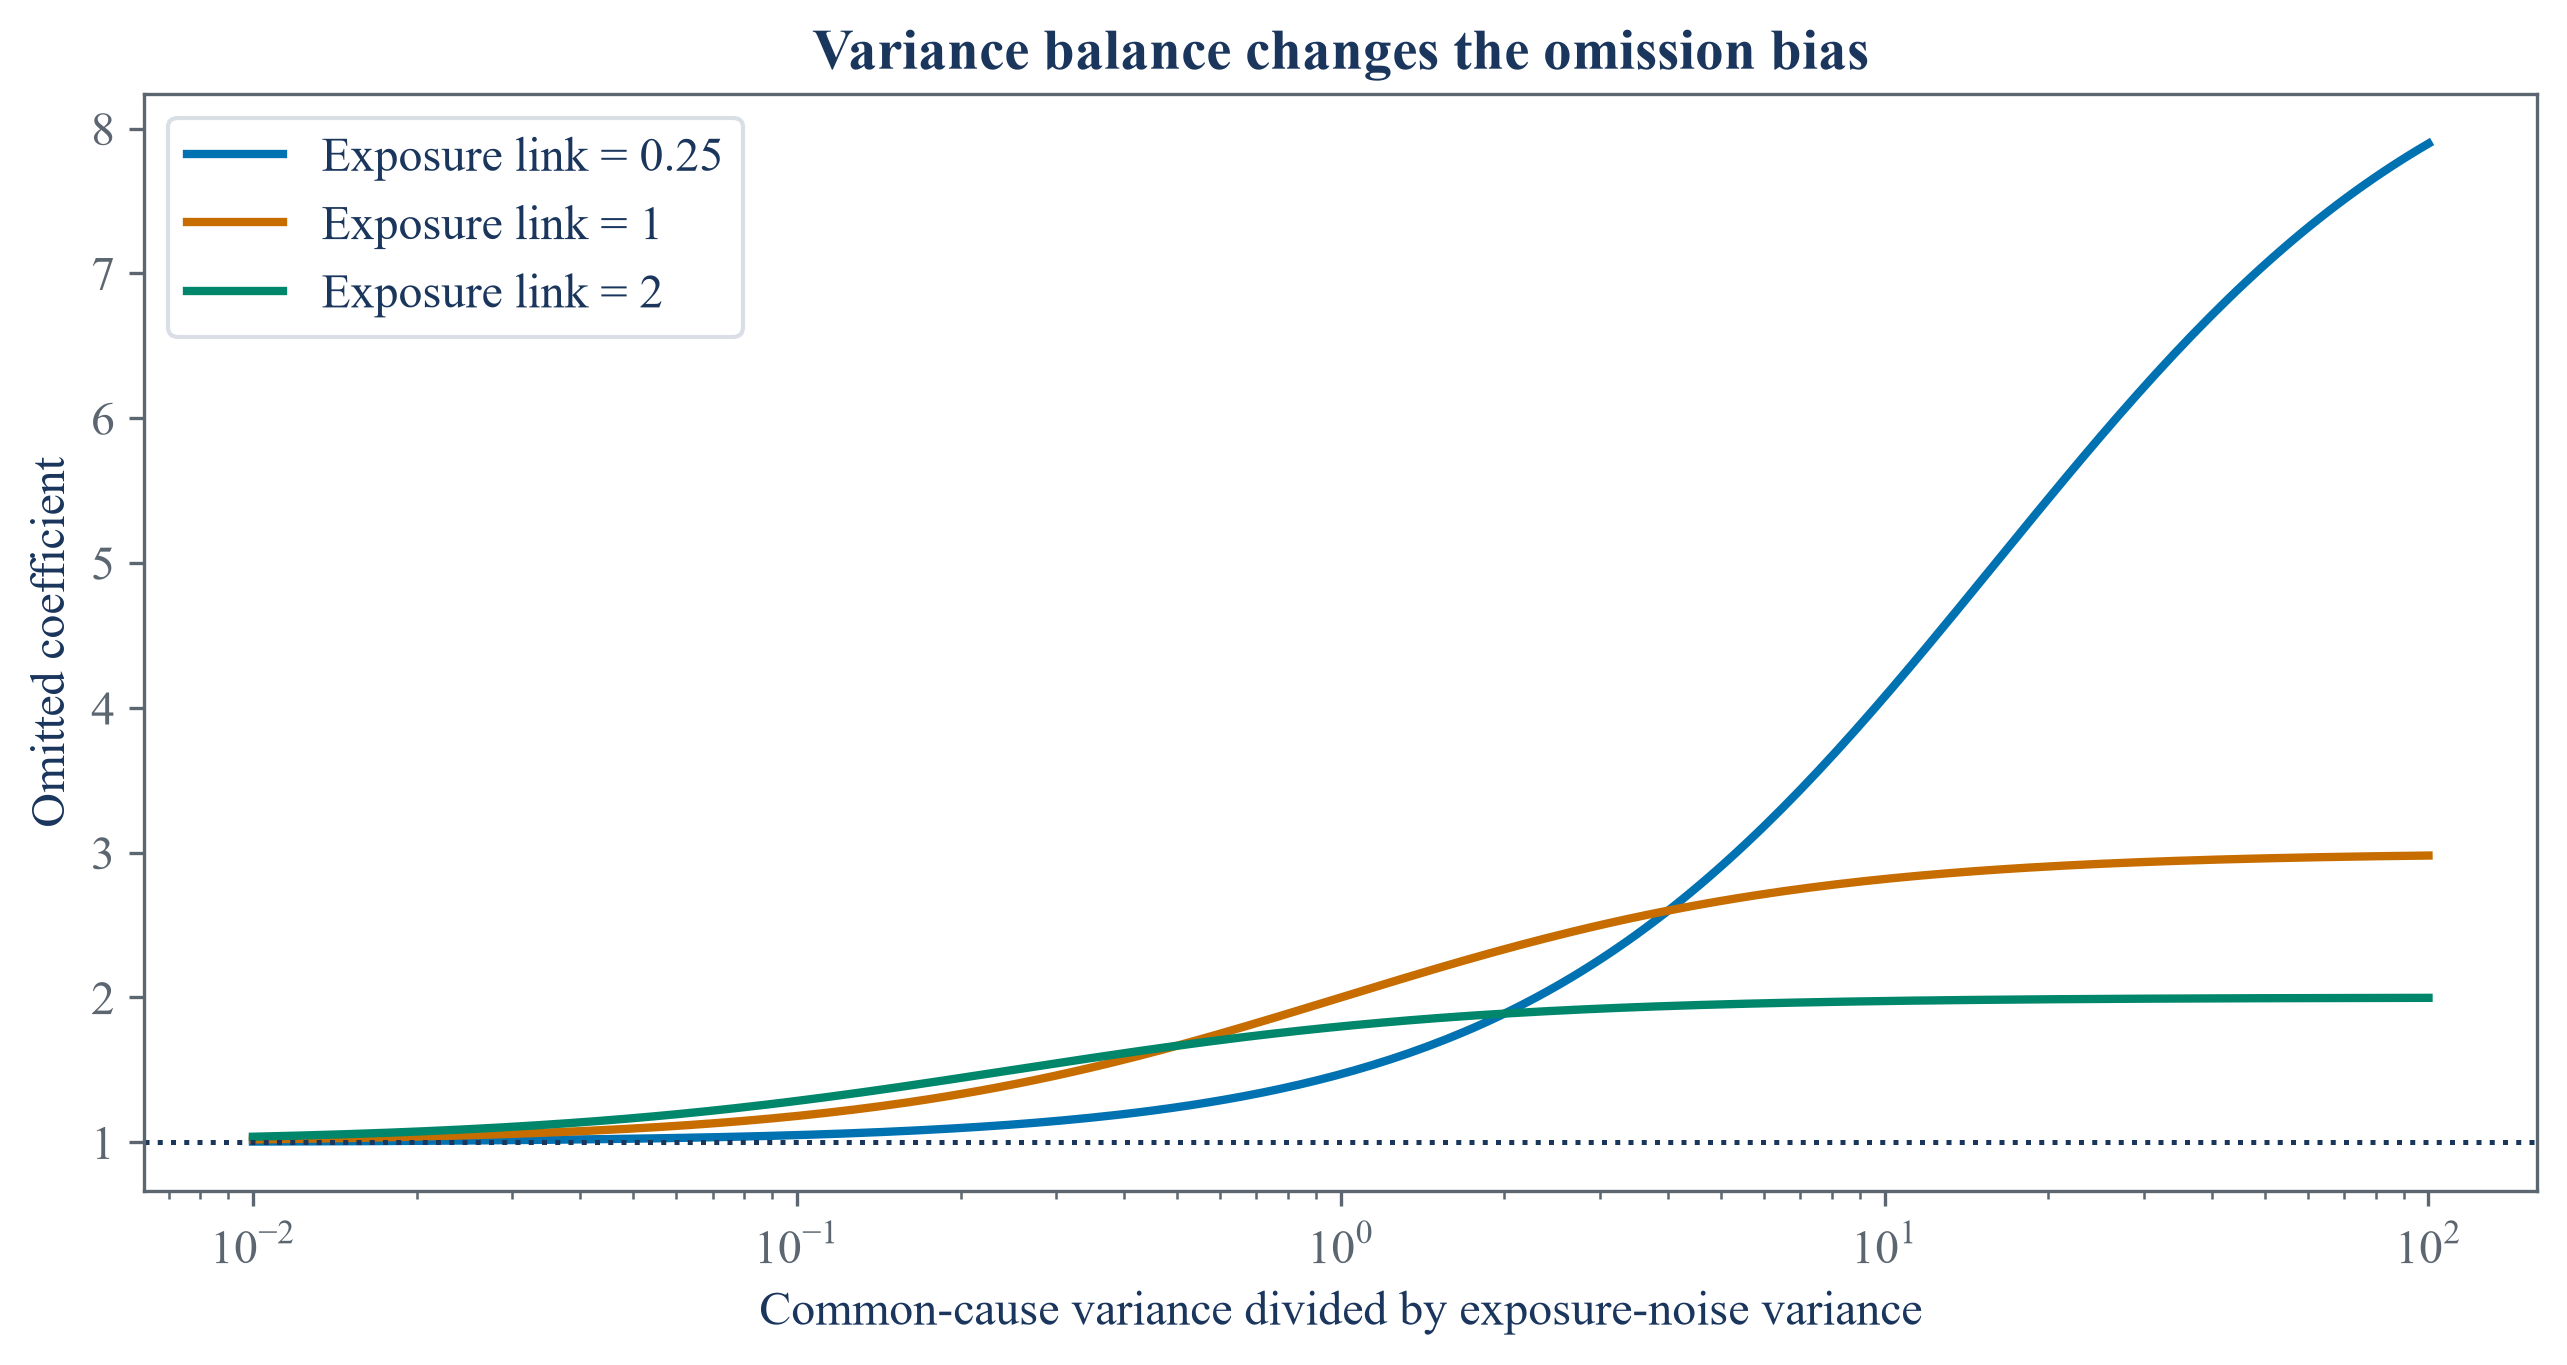

In [2]:
variance_cases = [
    ("Released quickstart", 2.0, 3.0, 4.0, 5.0, 6.0),
    ("Unequal variances", 0.75, -1.25, 0.5, 2.0, 3.0),
    ("Small common-cause variance", -0.4, 2.5, -0.75, 0.25, 4.0),
    ("No outcome link", 1.5, 0.0, 8.0, 3.0, 0.5),
    ("Unit variances", 1.0, 3.0, 1.0, 1.0, 1.0),
]
variance_rows = []
for name, beta, gamma, delta, common_variance, noise_variance in variance_cases:
    result = generalized_confounder_undercontrolled_coefficient(beta, gamma, delta, confounder_variance=common_variance, exposure_noise_variance=noise_variance)
    covariance_ratio = beta + delta * gamma * common_variance / (delta ** 2 * common_variance + noise_variance)
    variance_rows.append({"Case": name, "Direct effect": beta, "Outcome link": gamma, "Exposure link": delta, "Common-cause variance": common_variance, "Exposure-noise variance": noise_variance, "Omitted coefficient": result, "Formula difference": result - covariance_ratio})
variance_table = pd.DataFrame(variance_rows)
save_table(variance_table, "confounder_general_variance", "Omitted coefficients with general positive variances.", "tab:chapter26-confounder-general-variance")
display(variance_table)

ratio_grid = np.logspace(-2, 2, 240)
figure, axis = plt.subplots(figsize=(8.7, 4.7))
for delta_value, color in [(0.25, palette["cyan"]), (1.0, palette["amber"]), (2.0, palette["green"])]:
    coefficients = [generalized_confounder_undercontrolled_coefficient(1.0, 2.0, delta_value, confounder_variance=ratio, exposure_noise_variance=1.0) for ratio in ratio_grid]
    axis.plot(ratio_grid, coefficients, color=color, linewidth=2, label=f"Exposure link = {delta_value:g}")
axis.axhline(1.0, color=palette["text"], linewidth=1.2, linestyle=":")
axis.set_xscale("log")
axis.set_xlabel("Common-cause variance divided by exposure-noise variance")
axis.set_ylabel("Omitted coefficient")
axis.set_title("Variance balance changes the omission bias")
axis.legend()
figure.tight_layout()
save_figure(figure, "confounder_variance_ratio")

## Translating conditional factor returns into forecasts

The correct and omitted-confounder expected returns are given by:

$$
\begin{aligned}
R_C(x,z)&=(\beta x+\gamma z)^2,
&R_U(x;\delta_e,\delta_r)&=x^2\widetilde\beta(\delta_e)\widetilde\beta(\delta_r),\\
F_C(\delta_r)&=\beta^2+(\beta\delta_r+\gamma)^2,
&F_U(\delta_e,\delta_r)&=(1+\delta_r^2)\widetilde\beta(\delta_e)\widetilde\beta(\delta_r).
\end{aligned}
$$

Here, $R_C$ and $R_U$ are the correct and omitted-confounder factor returns at exposure values $x$ and $z$, $F_C$ and $F_U$ are their forecast returns after averaging over the exposure distribution, $\delta_e$ is the confounder link estimated during training, $\delta_r$ is the realized link during use, and $\widetilde\beta(\delta)$ is the omitted coefficient evaluated at link $\delta$.

,Setting,Target,Correct return,Misspecified return,Difference
0,Fixed link,Factor return,16,6.25,9.75
1,Fixed link,Forecast return,17,12.5,4.5
2,Link changes from 1 to -1,Factor return,16,-1.25,17.25
3,Link changes from 1 to -1,Forecast return,5,-2.5,7.5


,Direct effect,Outcome link,Exposure link,Correct return,Misspecified return,Observed gap,Exact gap
0,1,3,1,17,12.5,4.5,4.5
1,-0.5,0.75,2,0.3125,0.2,0.1125,0.1125
2,2,-1,-0.25,6.25,5.308824,0.941176,0.941176


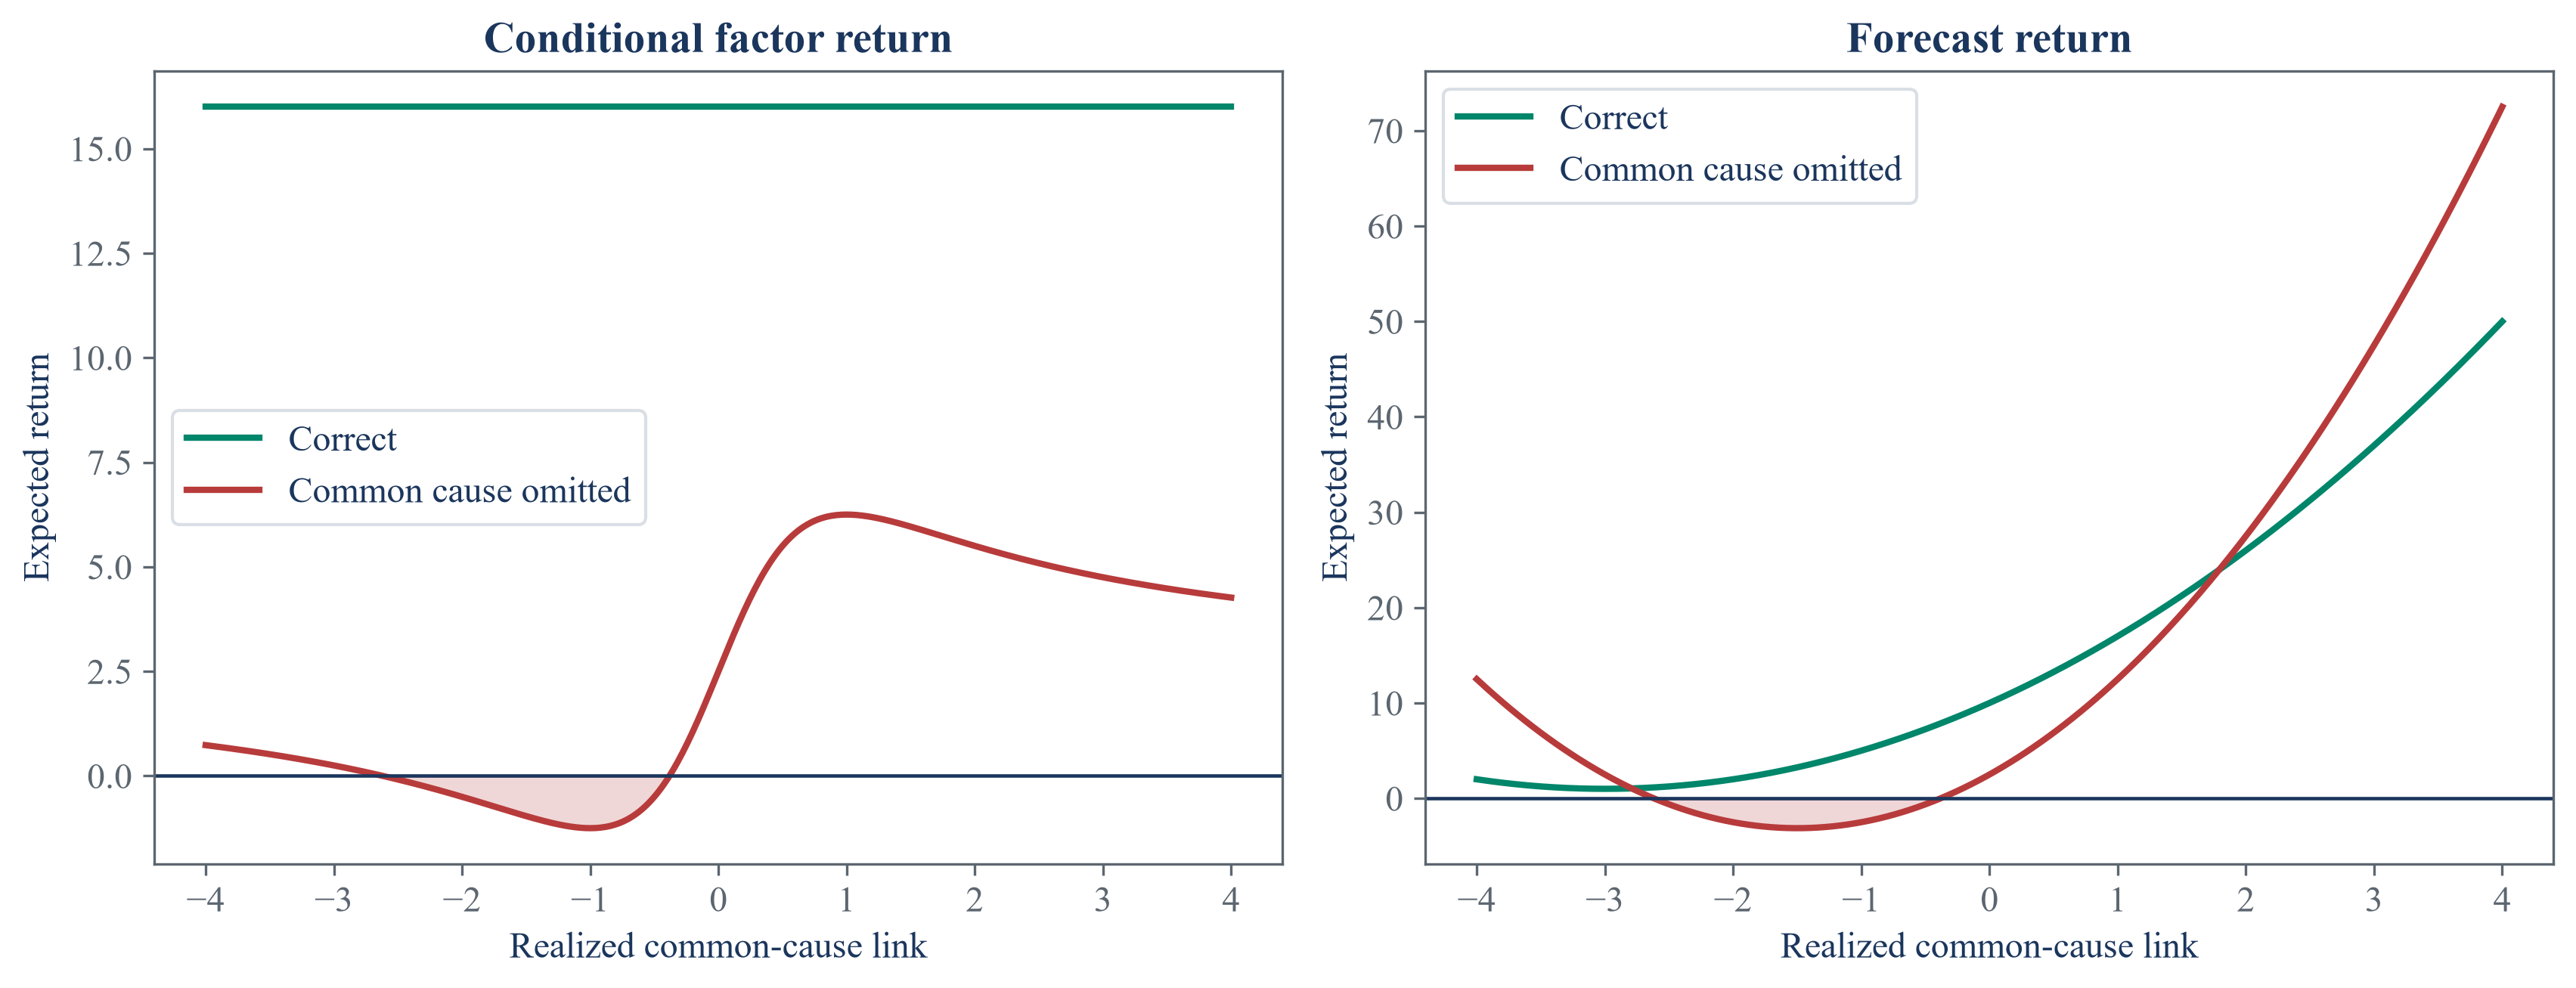

In [3]:
static_factor = confounder_factor_return(1.0, 1.0, 1.0, 3.0, 1.0)
static_forecast = confounder_forecast_return(1.0, 3.0, 1.0)
shifted_factor = confounder_factor_return(1.0, 1.0, 1.0, 3.0, 1.0, delta_realized=-1.0)
shifted_forecast = confounder_forecast_return(1.0, 3.0, 1.0, delta_realized=-1.0)
return_table = pd.DataFrame([
    {"Setting": "Fixed link", "Target": "Factor return", "Correct return": static_factor.correct, "Misspecified return": static_factor.misspecified, "Difference": static_factor.correct - static_factor.misspecified},
    {"Setting": "Fixed link", "Target": "Forecast return", "Correct return": static_forecast.correct, "Misspecified return": static_forecast.misspecified, "Difference": static_forecast.correct - static_forecast.misspecified},
    {"Setting": "Link changes from 1 to -1", "Target": "Factor return", "Correct return": shifted_factor.correct, "Misspecified return": shifted_factor.misspecified, "Difference": shifted_factor.correct - shifted_factor.misspecified},
    {"Setting": "Link changes from 1 to -1", "Target": "Forecast return", "Correct return": shifted_forecast.correct, "Misspecified return": shifted_forecast.misspecified, "Difference": shifted_forecast.correct - shifted_forecast.misspecified},
])
save_table(return_table, "confounder_return_examples", "Correct and omitted-confounder expected returns.", "tab:chapter26-confounder-return-examples")
display(return_table)

static_gap_cases = [(1.0, 3.0, 1.0), (-0.5, 0.75, 2.0), (2.0, -1.0, -0.25)]
gap_rows = []
for beta, gamma, delta in static_gap_cases:
    result = confounder_forecast_return(beta, gamma, delta)
    exact_gap = gamma ** 2 / (1.0 + delta ** 2)
    gap_rows.append({"Direct effect": beta, "Outcome link": gamma, "Exposure link": delta, "Correct return": result.correct, "Misspecified return": result.misspecified, "Observed gap": result.correct - result.misspecified, "Exact gap": exact_gap})
gap_table = pd.DataFrame(gap_rows)
save_table(gap_table, "confounder_static_gap", "The exact fixed-link forecast-return gap.", "tab:chapter26-confounder-static-gap")
display(gap_table)

realized_links = np.linspace(-4.0, 4.0, 401)
factor_correct = []
factor_misspecified = []
forecast_correct = []
forecast_misspecified = []
for realized_link in realized_links:
    factor_result = confounder_factor_return(1.0, 1.0, 1.0, 3.0, 1.0, delta_realized=realized_link)
    forecast_result = confounder_forecast_return(1.0, 3.0, 1.0, delta_realized=realized_link)
    factor_correct.append(factor_result.correct)
    factor_misspecified.append(factor_result.misspecified)
    forecast_correct.append(forecast_result.correct)
    forecast_misspecified.append(forecast_result.misspecified)
figure, axes = plt.subplots(1, 2, figsize=(11.5, 4.5))
for axis, correct_values, misspecified_values, title in [(axes[0], factor_correct, factor_misspecified, "Conditional factor return"), (axes[1], forecast_correct, forecast_misspecified, "Forecast return")]:
    axis.plot(realized_links, correct_values, color=palette["green"], linewidth=2, label="Correct")
    axis.plot(realized_links, misspecified_values, color=palette["rose"], linewidth=2, label="Common cause omitted")
    axis.axhline(0.0, color=palette["text"], linewidth=1.1)
    axis.fill_between(realized_links, misspecified_values, 0.0, where=np.asarray(misspecified_values) < 0.0, color=palette["rose"], alpha=0.2)
    axis.set_xlabel("Realized common-cause link")
    axis.set_ylabel("Expected return")
    axis.set_title(title)
    axis.legend()
figure.tight_layout()
save_figure(figure, "confounder_return_shift")

## Checking zero and sign boundaries

When $\beta\ne0$, the links where the omitted coefficient is zero solve:

$$
\beta\delta^2+\gamma\delta+\beta=0,
\qquad
\delta_{\pm}=\frac{-\gamma\pm\sqrt{\gamma^2-4\beta^2}}{2\beta}.
$$

Here, $\delta_-$ and $\delta_+$ are the two zero boundaries, $\beta$ is the direct exposure effect, $\gamma$ is the common-cause outcome link, and real boundaries exist when $\gamma^2\geq4\beta^2$.

,Location,Estimated link,Omitted coefficient,Shifted misspecified forecast return,Return sign
0,Lower root,-2.618034,0,0,Zero
1,Upper root,-0.381966,0,0,Zero
2,Between roots,-1,-0.5,-2.5,Negative
3,Outside roots,1,2.5,12.5,Positive


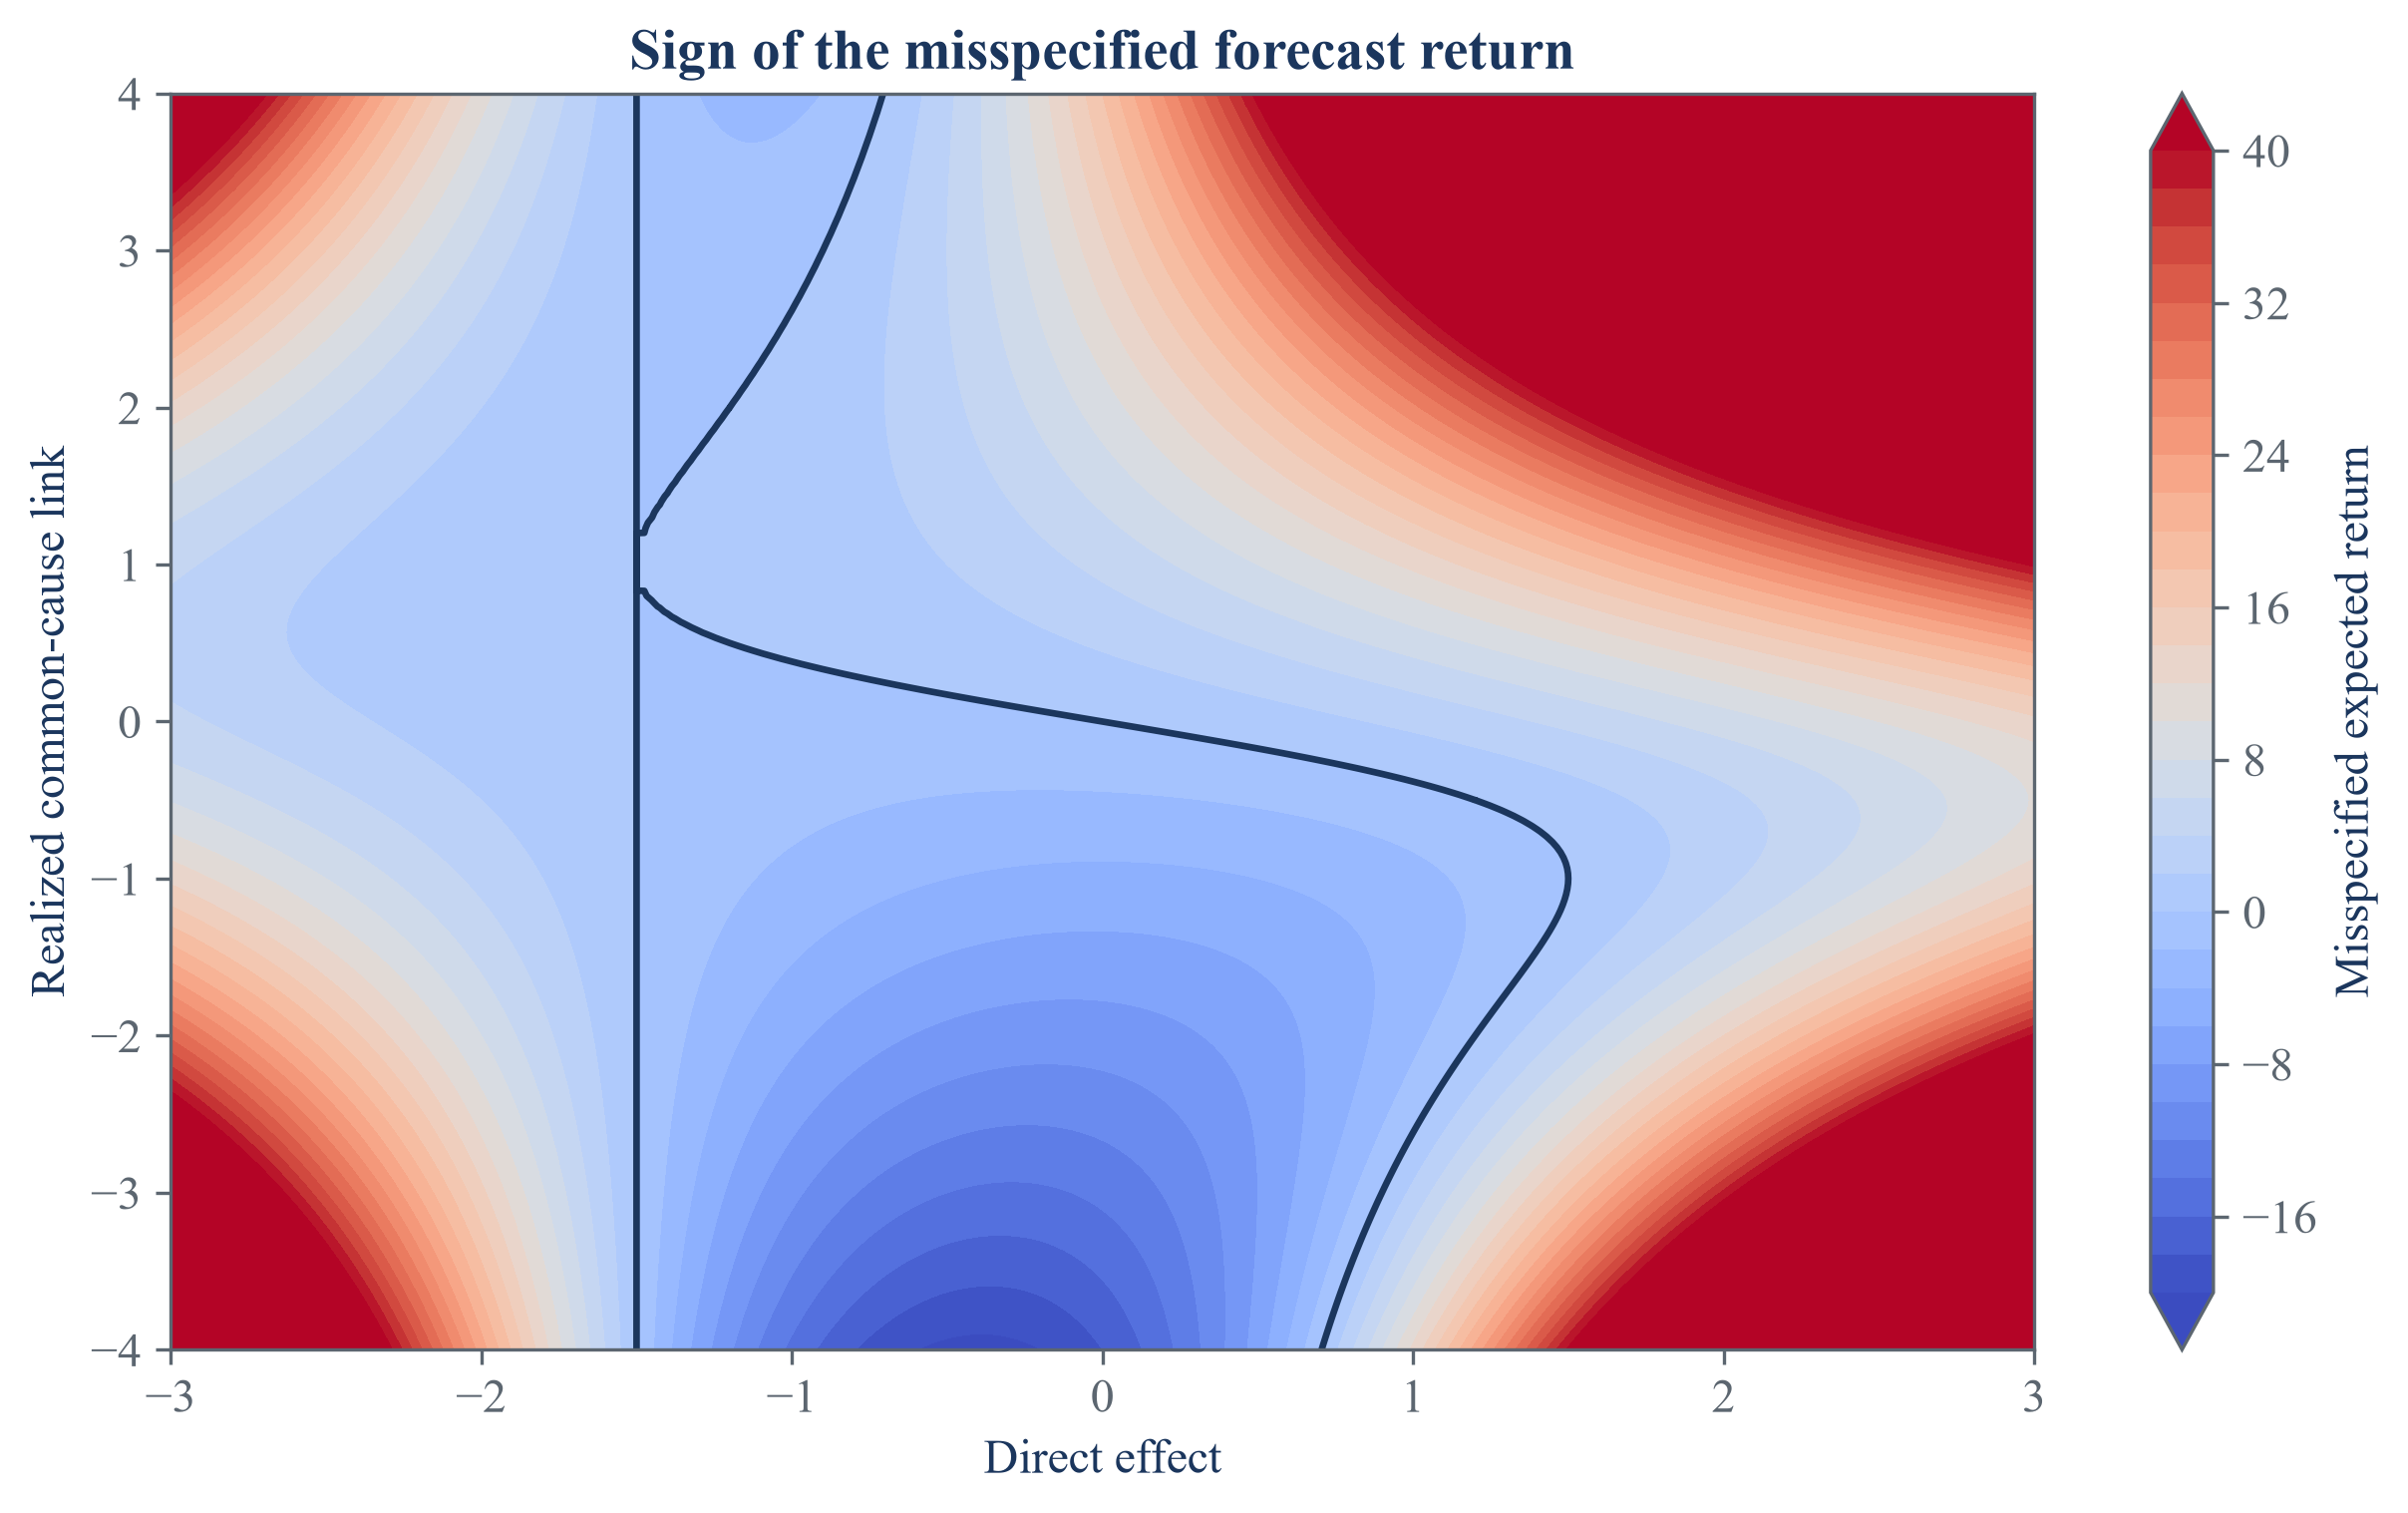

In [4]:
root_low = (-3.0 - math.sqrt(5.0)) / 2.0
root_high = (-3.0 + math.sqrt(5.0)) / 2.0
boundary_rows = []
for name, link in [("Lower root", root_low), ("Upper root", root_high), ("Between roots", -1.0), ("Outside roots", 1.0)]:
    coefficient = confounder_undercontrolled_coefficient(1.0, 3.0, link)
    forecast = confounder_forecast_return(1.0, 3.0, link, delta_realized=1.0)
    boundary_rows.append({"Location": name, "Estimated link": link, "Omitted coefficient": coefficient, "Shifted misspecified forecast return": forecast.misspecified, "Return sign": "Negative" if forecast.misspecified < 0.0 else "Zero" if abs(forecast.misspecified) < 2e-14 else "Positive"})
boundary_table = pd.DataFrame(boundary_rows)
save_table(boundary_table, "confounder_zero_boundaries", "Exact coefficient and shifted-return sign boundaries.", "tab:chapter26-confounder-zero-boundaries")
display(boundary_table)

beta_grid = np.linspace(-3.0, 3.0, 241)
realized_grid = np.linspace(-4.0, 4.0, 241)
beta_mesh, realized_mesh = np.meshgrid(beta_grid, realized_grid)
sign_values = np.empty_like(beta_mesh)
for row in range(sign_values.shape[0]):
    for column in range(sign_values.shape[1]):
        sign_values[row, column] = confounder_forecast_return(beta_mesh[row, column], 3.0, 1.0, delta_realized=realized_mesh[row, column]).misspecified
figure, axis = plt.subplots(figsize=(8.6, 5.2))
image = axis.contourf(beta_mesh, realized_mesh, sign_values, levels=np.linspace(-20, 40, 31), cmap="coolwarm", extend="both")
axis.contour(beta_mesh, realized_mesh, sign_values, levels=[0.0], colors=[palette["text"]], linewidths=1.6)
axis.set_xlabel("Direct effect")
axis.set_ylabel("Realized common-cause link")
axis.set_title("Sign of the misspecified forecast return")
figure.colorbar(image, ax=axis, label="Misspecified expected return")
figure.tight_layout()
save_figure(figure, "confounder_sign_regions")

## Checking numerical stability within valid inputs

In [5]:
input_checks = pd.DataFrame([
    contract_result("Boolean coefficient", lambda: confounder_undercontrolled_coefficient(True, 1.0, 1.0), "ValueError"),
    contract_result("Complex coefficient", lambda: confounder_undercontrolled_coefficient(1.0 + 2.0j, 1.0, 1.0), "ValueError"),
    contract_result("Nonfinite coefficient", lambda: confounder_forecast_return(np.inf, 1.0, 1.0), "ValueError"),
    contract_result("Zero common-cause variance", lambda: generalized_confounder_undercontrolled_coefficient(1.0, 2.0, 3.0, confounder_variance=0.0, exposure_noise_variance=1.0), "ValueError"),
    contract_result("Negative exposure-noise variance", lambda: generalized_confounder_undercontrolled_coefficient(1.0, 2.0, 3.0, confounder_variance=1.0, exposure_noise_variance=-1.0), "ValueError"),
    contract_result("Required variance arguments omitted", lambda: generalized_confounder_undercontrolled_coefficient(1.0, 2.0, 3.0), "TypeError"),
    contract_result("Variance arguments supplied by position", lambda: generalized_confounder_undercontrolled_coefficient(1.0, 2.0, 3.0, 1.0, 1.0), "TypeError"),
])
save_table(input_checks, "confounder_input_checks", "Input-boundary checks for omitted-confounder calculations.", "tab:chapter26-confounder-input-checks")
display(input_checks)

extreme_coefficient = confounder_undercontrolled_coefficient(0.0, 1e308, 1e308)
extreme_factor = confounder_factor_return(1e200, 0.0, 1e-200, 0.0, 1.0)
sign_boundary = confounder_undercontrolled_coefficient(1.0, 1e10, -1e-10)
numerical_table = pd.DataFrame([
    {"Check": "Large links retain a finite coefficient", "Value": extreme_coefficient, "Expected value": 1.0, "Passed": np.isclose(extreme_coefficient, 1.0, rtol=1e-15)},
    {"Check": "Scaled factor return stays representable", "Value": extreme_factor.correct, "Expected value": 1.0, "Passed": np.isclose(extreme_factor.correct, 1.0, rtol=1e-15)},
    {"Check": "Scaled misspecified return stays representable", "Value": extreme_factor.misspecified, "Expected value": 1.0, "Passed": np.isclose(extreme_factor.misspecified, 1.0, rtol=1e-15)},
    {"Check": "Negative sign survives near cancellation", "Value": sign_boundary, "Expected value": -3.642219731549774e-17, "Passed": sign_boundary < 0.0},
])
save_table(numerical_table, "confounder_numerical_stability", "Finite-scaling and sign-preservation checks.", "tab:chapter26-confounder-numerical-stability", float_format="%.12g")
display(numerical_table)

section_summary = pd.DataFrame([
    {"Question": "What creates the coefficient error?", "Answer": "Omitting the common cause"},
    {"Question": "When does the unit-variance bias vanish?", "Answer": "When either common-cause link is zero"},
    {"Question": "Is the fixed-link forecast gap negative?", "Answer": "No"},
    {"Question": "Can a link change make the misspecified return negative?", "Answer": "Yes"},
    {"Question": "Does the calculation prove a market graph?", "Answer": "No"},
])
save_table(section_summary, "confounder_section_summary", "Main conclusions from the omitted-confounder experiments.", "tab:chapter26-confounder-section-summary")
display(section_summary)

,Check,Expected result,Observed result,Passed
0,Boolean coefficient,ValueError,ValueError,True
1,Complex coefficient,ValueError,ValueError,True
2,Nonfinite coefficient,ValueError,ValueError,True
3,Zero common-cause variance,ValueError,ValueError,True
4,Negative exposure-noise variance,ValueError,ValueError,True
5,Required variance arguments omitted,TypeError,TypeError,True
6,Variance arguments supplied by position,TypeError,TypeError,True


,Check,Value,Expected value,Passed
0,Large links retain a finite coefficient,1,1,True
1,Scaled factor return stays representable,1,1,True
2,Scaled misspecified return stays representable,1,1,True
3,Negative sign survives near cancellation,0,0,True


,Question,Answer
0,What creates the coefficient error?,Omitting the common cause
1,When does the unit-variance bias vanish?,When either common-cause link is zero
2,Is the fixed-link forecast gap negative?,No
3,Can a link change make the misspecified return...,Yes
4,Does the calculation prove a market graph?,No


## Tests

In [6]:
assert confounder_undercontrolled_coefficient(1.0, 3.0, 1.0) == 2.5
assert generalized_confounder_undercontrolled_coefficient(2.0, 3.0, 4.0, confounder_variance=5.0, exposure_noise_variance=6.0) == 116.0 / 43.0
assert static_factor == StrategyPerformance(correct=16.0, misspecified=6.25)
assert static_forecast == StrategyPerformance(correct=17.0, misspecified=12.5)
assert shifted_factor == StrategyPerformance(correct=16.0, misspecified=-1.25)
assert shifted_forecast == StrategyPerformance(correct=5.0, misspecified=-2.5)
assert np.allclose(gap_table["Observed gap"], gap_table["Exact gap"])
assert abs(boundary_table.loc[boundary_table["Location"] == "Upper root", "Omitted coefficient"].iloc[0]) < 2e-15
assert input_checks["Passed"].all()
assert numerical_table["Passed"].all()
for stem in ["confounder_graph_and_bias", "confounder_variance_ratio", "confounder_return_shift", "confounder_sign_regions"]:
    assert (FIGURES / f"{stem}.pdf").is_file()
for stem in ["confounder_standardized_coefficients", "confounder_generated_check", "confounder_general_variance", "confounder_return_examples", "confounder_static_gap", "confounder_zero_boundaries", "confounder_input_checks", "confounder_numerical_stability", "confounder_section_summary"]:
    assert (TABLES / f"{stem}.tex").is_file()